In [1]:
#All the imports
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm
from scipy.stats import kurtosis
import fifpy

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import compute_radial_spectrum, partial_x_fft, partial_y_fft
from shared.filtering import k_to_mask_length, iterative_filtering1D, iterative_filtering3D
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir
RESULTS = results_dir("paper1_methods")

In [2]:
def band_pass_k(field, k_low, k_high, Xi=1.6, verbose=False):
    """Keep the scales between k_low and k_high, by setting the two mask lengths
    directly instead of counting IMFs.
 
    Ask MIF for two components with mask lengths L(k_high) < L(k_low). Then:
        IMC[0]  scales finer  than k_high   (dropped)
        IMC[1]  the band  k_low < k < k_high   <-- returned
        IMC[2]  residual, coarser than k_low   (dropped)
 
    This is the version worth preferring: the band edges are the same in every
    snapshot, so results are comparable across time and across runs. Index-based
    bands drift, because MIF chooses them adaptively from each field.
 
    Needs k_to_mask_length from your session. Larger k = finer scale = shorter
    mask, so the mask lengths go in the opposite order to the wavenumbers.
    """
    if not k_low < k_high:
        raise ValueError(f"need k_low < k_high, got {k_low}, {k_high}")
 
    L_fine   = k_to_mask_length(k_high)        # short mask  -> the finer edge
    L_coarse = k_to_mask_length(k_low, prefactor=2.0)         # long mask   -> the coarser edge
    if L_fine >= L_coarse:
        raise ValueError(f"mask lengths came out {L_fine} and {L_coarse}; the band is "
                         "too narrow for the grid to resolve")
 
    fif = fifpy.MIF(NIMFs=2, alpha=30, Xi=Xi)
    fif.run(field, M=[int(L_fine), int(L_coarse)])   # M must be a SEQUENCE
    if verbose:
        print(f"IMC.shape = {fif.IMC.shape}   masks {int(L_fine)}, {int(L_coarse)} px "
              f"for k = {k_high}, {k_low}")
    return fif.IMC[1]                          # the middle component IS the band

def _mask(k, field, what, prefactor=None):
    """Mask length for a cut at k, with a check that it fits the field."""
    p = PREFACTOR if prefactor is None else prefactor
    L = int(k_to_mask_length(k, prefactor=p))
    n = min(np.shape(field))
    if L < 2:
        raise ValueError(f"{what}: k={k} needs a mask of {L} px, below the grid "
                         "scale -- there is nothing there to remove")
    if L > n // 4:
        print(f"  WARNING: {what} at k={k} needs a mask of {L} px, "
              f"{100*L/n:.0f}% of the {n}-point field. fifpy may cap it, in which "
              "case the cut lands at a higher k than you asked for.")
    return L
 
 
def low_pass_k(field, k, Xi=1.6, prefactor=1.0, verbose=False):
    """Keep the scales COARSER than k, i.e. remove everything finer.
 
    One decomposition at mask length L(k):
        IMC[0]  finer than k    (dropped)
        IMC[1]  the rest        <-- returned
    This is the same thing iterative_filtering1DWithKCutOff does.
    """
    L = _mask(k, field, "low-pass", prefactor)
    fif = fifpy.MIF(NIMFs=1, alpha=30, Xi=Xi)
    fif.run(field, M=[L])                       # M must be a SEQUENCE
    if verbose:
        print(f"IMC.shape = {fif.IMC.shape}   mask {L} px for k = {k}  (low-pass)")
    return np.sum(fif.IMC[1:], axis=0)
 
 
def high_pass_k(field, k, Xi=1.6, prefactor=2.0, verbose=False):
    """Keep the scales FINER than k, i.e. remove everything coarser.
 
    The SAME decomposition as low_pass_k, but the other component returned:
        IMC[0]  finer than k    <-- returned
        IMC[1]  the rest        (dropped)
    """
    L = _mask(k, field, "high-pass", prefactor)
    fif = fifpy.MIF(NIMFs=1, alpha=30, Xi=Xi)
    fif.run(field, M=[L])
    if verbose:
        print(f"IMC.shape = {fif.IMC.shape}   mask {L} px for k = {k}  (high-pass)")
    return fif.IMC[0]

In [3]:
# List of simulation directories

dx = 0.0625
dy = 0.0625

In [4]:
# Plotting Power Spectrum at reconnection time

base_path = f"{DATA_ROOT}/beta_p_1/beta_e_1"

time = 200
k_low = 1.6
k_high = 2.2

File_Bx = f"{base_path}/Bx_ApJ_t{time}.h5"

with h5py.File(File_Bx, 'r') as fBx:
    data_Bx = fBx['DS1'][:].T

# Compute radial spectra
spectrum_Bx = compute_radial_spectrum(data_Bx, dx, dy)

data_band_pass_Bx = band_pass_k(data_Bx, k_low, k_high)

spectrum_Band_pass_Bx = compute_radial_spectrum(data_band_pass_Bx, dx, dy)

IMF 1
IMF 2


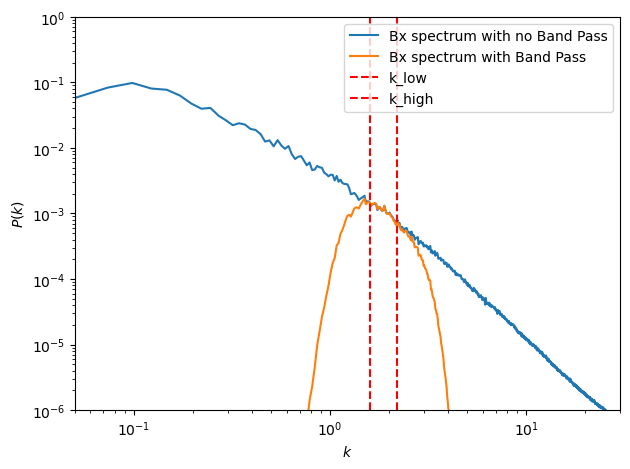

In [5]:
# Plot unfiltered first and capture line objects
plt.rcdefaults()

plt.loglog(
    spectrum_Bx.kk,
    spectrum_Bx.sp,
    linestyle="-",
    label="Bx spectrum with no Band Pass"
)

plt.loglog(
    spectrum_Band_pass_Bx.kk,
    spectrum_Band_pass_Bx.sp,
    linestyle="-",
    label="Bx spectrum with Band Pass"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
plt.axvline(x=k_low, linestyle='--', color='red', label='k_low')
plt.axvline(x=k_high, linestyle='--', color='red', label='k_high')


plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "JB_Spectrum", dpi=300)
plt.show()

In [6]:
data_low_pass_Bx = low_pass_k(data_Bx, k_high)
spectrum_low_pass_Bx = compute_radial_spectrum(data_low_pass_Bx, dx, dy)

IMF 1


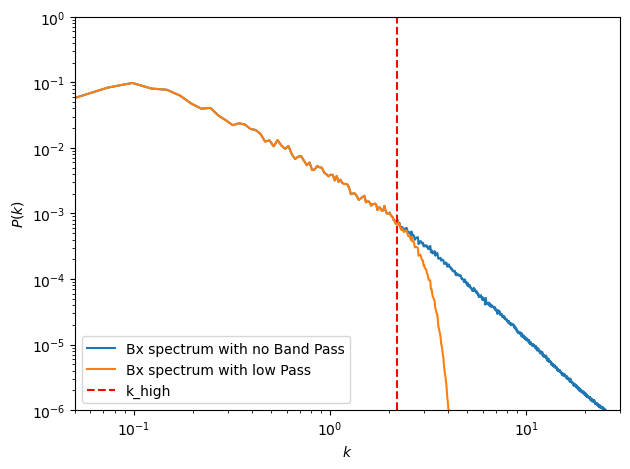

In [7]:
# Plot unfiltered first and capture line objects
plt.rcdefaults()

plt.loglog(
    spectrum_Bx.kk,
    spectrum_Bx.sp,
    linestyle="-",
    label="Bx spectrum with no Band Pass"
)

plt.loglog(
    spectrum_low_pass_Bx.kk,
    spectrum_low_pass_Bx.sp,
    linestyle="-",
    label="Bx spectrum with low Pass"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
# plt.axvline(x=k_low, linestyle='--', color='red', label='k_low')
plt.axvline(x=k_high, linestyle='--', color='red', label='k_high')


plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "JB_Spectrum", dpi=300)
plt.show()

In [8]:
data_high_pass_Bx = high_pass_k(data_Bx, k_low)
spectrum_high_pass_Bx = compute_radial_spectrum(data_high_pass_Bx, dx, dy)

IMF 1


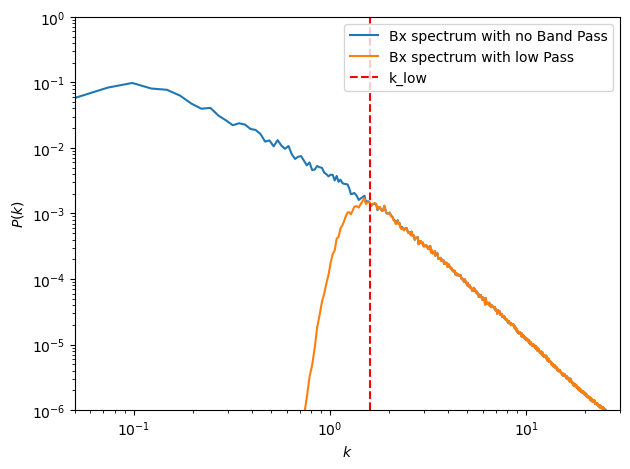

In [9]:
# Plot unfiltered first and capture line objects
plt.rcdefaults()

plt.loglog(
    spectrum_Bx.kk,
    spectrum_Bx.sp,
    linestyle="-",
    label="Bx spectrum with no Band Pass"
)

plt.loglog(
    spectrum_high_pass_Bx.kk,
    spectrum_high_pass_Bx.sp,
    linestyle="-",
    label="Bx spectrum with low Pass"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
plt.axvline(x=k_low, linestyle='--', color='red', label='k_low')
# plt.axvline(x=k_high, linestyle='--', color='red', label='k_high')


plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "JB_Spectrum", dpi=300)
plt.show()

In [10]:
File_Bx = f"{base_path}/Bx_ApJ_t{time}.h5"
File_By = f"{base_path}/By_ApJ_t{time}.h5"
File_Bz = f"{base_path}/Bz_ApJ_t{time}.h5"

with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:

        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T

# Compute radial spectra
spectrum_Bx = compute_radial_spectrum(data_Bx, dx, dy)
spectrum_By = compute_radial_spectrum(data_By, dx, dy)
spectrum_Bz = compute_radial_spectrum(data_Bz, dx, dy)
spectrum_B = np.recarray(spectrum_Bx.shape, dtype=spectrum_Bx.dtype)
spectrum_B.kk = spectrum_Bx.kk
spectrum_B.sp = spectrum_Bx.sp + spectrum_By.sp + spectrum_Bz.sp

data_Bx_filtered = band_pass_k(data_Bx, k_low, k_high)
data_By_filtered = band_pass_k(data_By, k_low, k_high)
data_Bz_filtered = band_pass_k(data_Bz, k_low, k_high)

spectrum_Bxf = compute_radial_spectrum(data_Bx_filtered, dx, dy)
spectrum_Byf = compute_radial_spectrum(data_By_filtered, dx, dy)
spectrum_Bzf = compute_radial_spectrum(data_Bz_filtered, dx, dy)

spectrum_Bf = np.recarray(spectrum_Bxf.shape, dtype=spectrum_Bxf.dtype)
spectrum_Bf.kk = spectrum_Bxf.kk
spectrum_Bf.sp = spectrum_Bxf.sp + spectrum_Byf.sp + spectrum_Bzf.sp

IMF 1
IMF 2
IMF 1
IMF 2
IMF 1
IMF 2


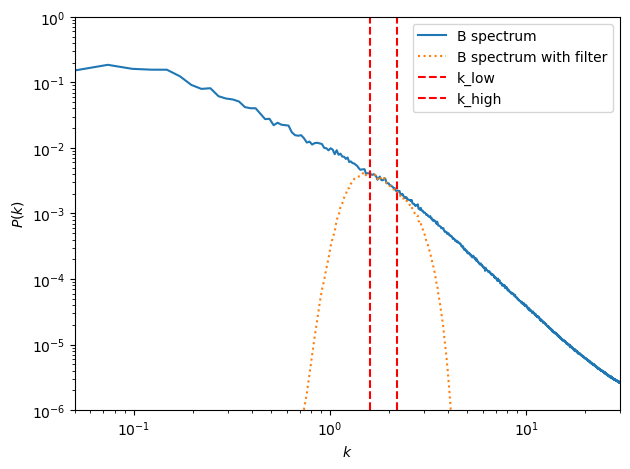

In [11]:
# Plot unfiltered first and capture line objects
plt.rcdefaults()

line_B, = plt.loglog(
    spectrum_B.kk,
    spectrum_B.sp,
    label="B spectrum"
)

plt.loglog(
    spectrum_Bf.kk,
    spectrum_Bf.sp,
    linestyle=":",
    label="B spectrum with filter"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
plt.axvline(x=k_low, linestyle='--', color='red', label='k_low')
plt.axvline(x=k_high, linestyle='--', color='red', label='k_high')

plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "JB_Spectrum", dpi=300)
plt.show()

In [12]:
data_Jx =  partial_y_fft(data_Bz, dx)
data_Jy = -partial_x_fft(data_Bz, dx)
data_Jz =  partial_x_fft(data_By, dx) - partial_y_fft(data_Bx, dx)

spectrum_Jx = compute_radial_spectrum(data_Jx, dx, dy)
spectrum_Jy = compute_radial_spectrum(data_Jy, dx, dy)
spectrum_Jz = compute_radial_spectrum(data_Jz, dx, dy)

spectrum_J = np.recarray(spectrum_Jx.shape, dtype=spectrum_Jx.dtype)
spectrum_J.kk = spectrum_Jx.kk
spectrum_J.sp = spectrum_Jx.sp + spectrum_Jy.sp + spectrum_Jz.sp

data_Jx_filtered = partial_y_fft(data_Bz_filtered,dx)
data_Jy_filtered = -partial_x_fft(data_Bz_filtered,dy)
data_Jz_filtered = partial_x_fft(data_By_filtered,dy)-partial_y_fft(data_Bx_filtered,dx)

spectrum_Jxf = compute_radial_spectrum(data_Jx_filtered, dx, dy)
spectrum_Jyf = compute_radial_spectrum(data_Jy_filtered, dx, dy)
spectrum_Jzf = compute_radial_spectrum(data_Jz_filtered, dx, dy)

spectrum_Jf = np.recarray(spectrum_Jxf.shape, dtype=spectrum_Jxf.dtype)
spectrum_Jf.kk = spectrum_Jxf.kk
spectrum_Jf.sp = spectrum_Jxf.sp + spectrum_Jyf.sp + spectrum_Jzf.sp

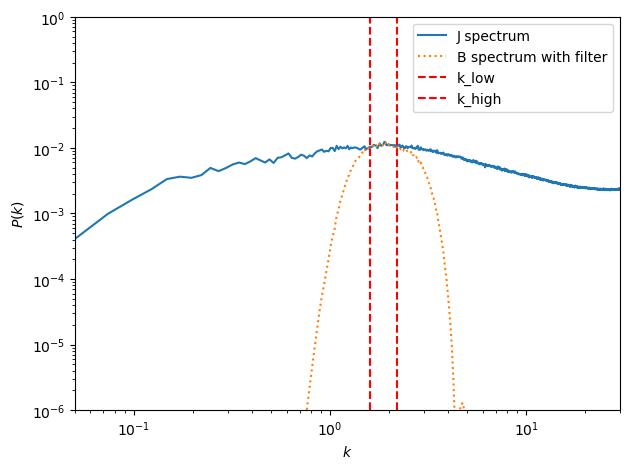

In [13]:
# Plot unfiltered first and capture line objects
plt.rcdefaults()

line_J, = plt.loglog(
    spectrum_J.kk,
    spectrum_J.sp,
    label="J spectrum"
)

plt.loglog(
    spectrum_Jf.kk,
    spectrum_Jf.sp,
    linestyle=":",
    label="B spectrum with filter"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
plt.axvline(x=k_low, linestyle='--', color='red', label='k_low')
plt.axvline(x=k_high, linestyle='--', color='red', label='k_high')

plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "JB_Spectrum", dpi=300)
plt.show()

In [14]:
k_peak = spectrum_J.kk[np.argmax(spectrum_J.sp)]
print(f"J spectrum peaks at k = {k_peak:.3f}  (scale 2*pi/k = {2*np.pi/k_peak:.3f} d_i)")

J spectrum peaks at k = 1.890  (scale 2*pi/k = 3.325 d_i)


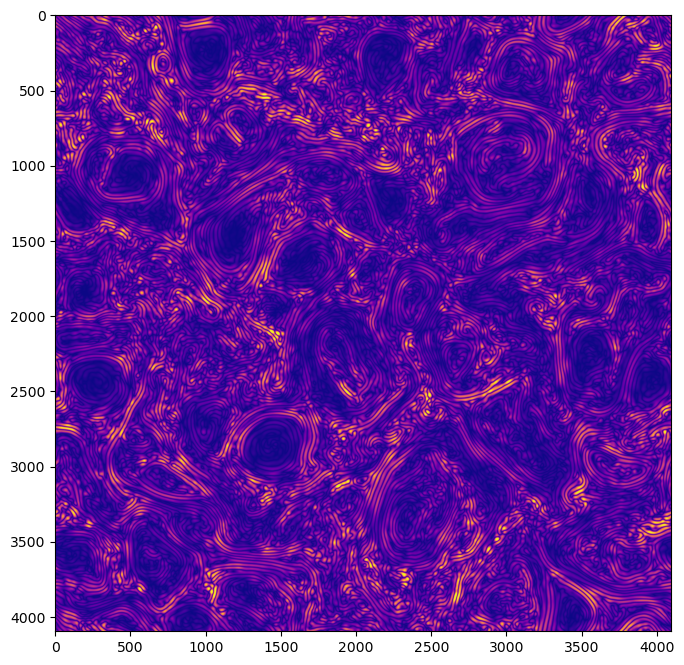

In [15]:
# 2. Plot the 2D matrix
plt.figure(figsize=(10, 8))
data_mod_Jz_filtered = np.abs(data_Jz_filtered)

# Basic image plot
img = plt.imshow(data_mod_Jz_filtered, cmap='plasma', vmax=0.5)  # You can change the colormap (e.g., 'hot', 'plasma', 'gray')

# Add titles and labels

# Show the plot
# plt.savefig("B.png", dpi = 5000)
plt.show()

In [16]:
#Low pass Filter

File_Bx = f"{base_path}/Bx_ApJ_t{time}.h5"
File_By = f"{base_path}/By_ApJ_t{time}.h5"
File_Bz = f"{base_path}/Bz_ApJ_t{time}.h5"

with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:

        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T

# Compute radial spectra
spectrum_Bx = compute_radial_spectrum(data_Bx, dx, dy)
spectrum_By = compute_radial_spectrum(data_By, dx, dy)
spectrum_Bz = compute_radial_spectrum(data_Bz, dx, dy)
spectrum_B = np.recarray(spectrum_Bx.shape, dtype=spectrum_Bx.dtype)
spectrum_B.kk = spectrum_Bx.kk
spectrum_B.sp = spectrum_Bx.sp + spectrum_By.sp + spectrum_Bz.sp

data_Bx_filtered = low_pass_k(data_Bx, k_high)
data_By_filtered = low_pass_k(data_By, k_high)
data_Bz_filtered = low_pass_k(data_Bz, k_high)

spectrum_Bxf = compute_radial_spectrum(data_Bx_filtered, dx, dy)
spectrum_Byf = compute_radial_spectrum(data_By_filtered, dx, dy)
spectrum_Bzf = compute_radial_spectrum(data_Bz_filtered, dx, dy)

spectrum_Bf = np.recarray(spectrum_Bxf.shape, dtype=spectrum_Bxf.dtype)
spectrum_Bf.kk = spectrum_Bxf.kk
spectrum_Bf.sp = spectrum_Bxf.sp + spectrum_Byf.sp + spectrum_Bzf.sp

IMF 1
IMF 1
IMF 1


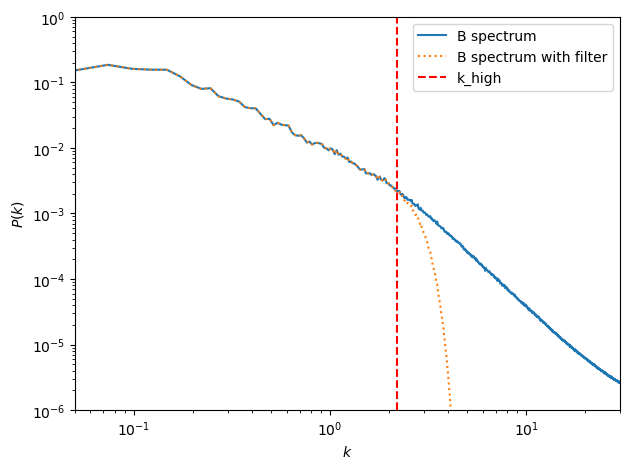

In [17]:
# Plot unfiltered first and capture line objects
plt.rcdefaults()

line_B, = plt.loglog(
    spectrum_B.kk,
    spectrum_B.sp,
    label="B spectrum"
)

plt.loglog(
    spectrum_Bf.kk,
    spectrum_Bf.sp,
    linestyle=":",
    label="B spectrum with filter"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
plt.axvline(x=k_high, linestyle='--', color='red', label='k_high')

plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "B_Spectrum", dpi=300)
plt.show()

In [18]:
data_Jx =  partial_y_fft(data_Bz, dx)
data_Jy = -partial_x_fft(data_Bz, dx)
data_Jz =  partial_x_fft(data_By, dx) - partial_y_fft(data_Bx, dx)

spectrum_Jx = compute_radial_spectrum(data_Jx, dx, dy)
spectrum_Jy = compute_radial_spectrum(data_Jy, dx, dy)
spectrum_Jz = compute_radial_spectrum(data_Jz, dx, dy)

spectrum_J = np.recarray(spectrum_Jx.shape, dtype=spectrum_Jx.dtype)
spectrum_J.kk = spectrum_Jx.kk
spectrum_J.sp = spectrum_Jx.sp + spectrum_Jy.sp + spectrum_Jz.sp

data_Jx_filtered = partial_y_fft(data_Bz_filtered,dx)
data_Jy_filtered = -partial_x_fft(data_Bz_filtered,dy)
data_Jz_filtered = partial_x_fft(data_By_filtered,dy)-partial_y_fft(data_Bx_filtered,dx)

spectrum_Jxf = compute_radial_spectrum(data_Jx_filtered, dx, dy)
spectrum_Jyf = compute_radial_spectrum(data_Jy_filtered, dx, dy)
spectrum_Jzf = compute_radial_spectrum(data_Jz_filtered, dx, dy)

spectrum_Jf = np.recarray(spectrum_Jxf.shape, dtype=spectrum_Jxf.dtype)
spectrum_Jf.kk = spectrum_Jxf.kk
spectrum_Jf.sp = spectrum_Jxf.sp + spectrum_Jyf.sp + spectrum_Jzf.sp

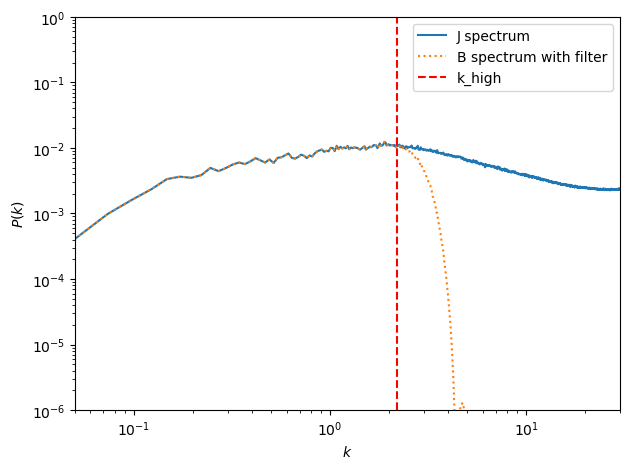

In [19]:
# Plot unfiltered first and capture line objects
plt.rcdefaults()

line_J, = plt.loglog(
    spectrum_J.kk,
    spectrum_J.sp,
    label="J spectrum"
)

plt.loglog(
    spectrum_Jf.kk,
    spectrum_Jf.sp,
    linestyle=":",
    label="B spectrum with filter"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
plt.axvline(x=k_high, linestyle='--', color='red', label='k_high')

plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "J_Spectrum", dpi=300)
plt.show()

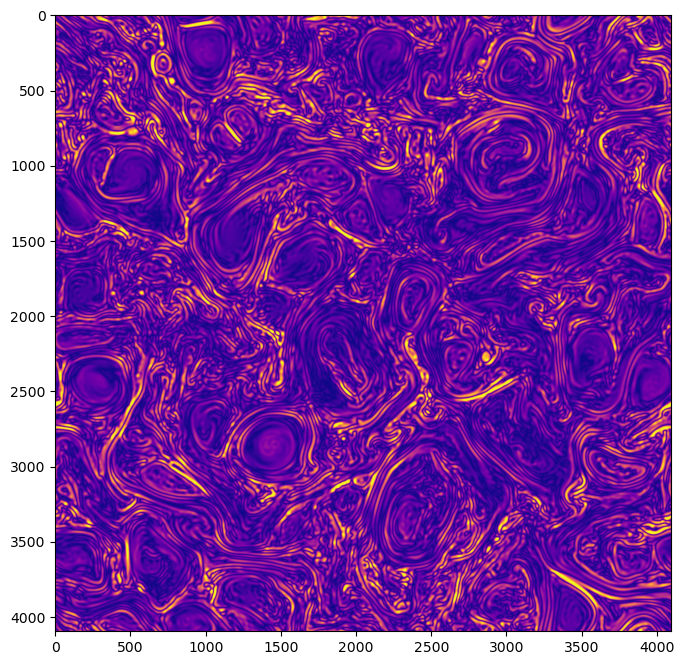

In [20]:
# 2. Plot the 2D matrix
plt.figure(figsize=(10, 8))
data_mod_Jz_filtered = np.abs(data_Jz_filtered)

# Basic image plot
img = plt.imshow(data_mod_Jz_filtered, cmap='plasma', vmax=0.5)  # You can change the colormap (e.g., 'hot', 'plasma', 'gray')

# Add titles and labels

# Show the plot
# plt.savefig("B.png", dpi = 5000)
plt.show()

In [21]:
#High pass Filter

File_Bx = f"{base_path}/Bx_ApJ_t{time}.h5"
File_By = f"{base_path}/By_ApJ_t{time}.h5"
File_Bz = f"{base_path}/Bz_ApJ_t{time}.h5"

with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:

        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T

# Compute radial spectra
spectrum_Bx = compute_radial_spectrum(data_Bx, dx, dy)
spectrum_By = compute_radial_spectrum(data_By, dx, dy)
spectrum_Bz = compute_radial_spectrum(data_Bz, dx, dy)
spectrum_B = np.recarray(spectrum_Bx.shape, dtype=spectrum_Bx.dtype)
spectrum_B.kk = spectrum_Bx.kk
spectrum_B.sp = spectrum_Bx.sp + spectrum_By.sp + spectrum_Bz.sp

data_Bx_filtered = high_pass_k(data_Bx, k_low)
data_By_filtered = high_pass_k(data_By, k_low)
data_Bz_filtered = high_pass_k(data_Bz, k_low)

spectrum_Bxf = compute_radial_spectrum(data_Bx_filtered, dx, dy)
spectrum_Byf = compute_radial_spectrum(data_By_filtered, dx, dy)
spectrum_Bzf = compute_radial_spectrum(data_Bz_filtered, dx, dy)

spectrum_Bf = np.recarray(spectrum_Bxf.shape, dtype=spectrum_Bxf.dtype)
spectrum_Bf.kk = spectrum_Bxf.kk
spectrum_Bf.sp = spectrum_Bxf.sp + spectrum_Byf.sp + spectrum_Bzf.sp

IMF 1
IMF 1
IMF 1


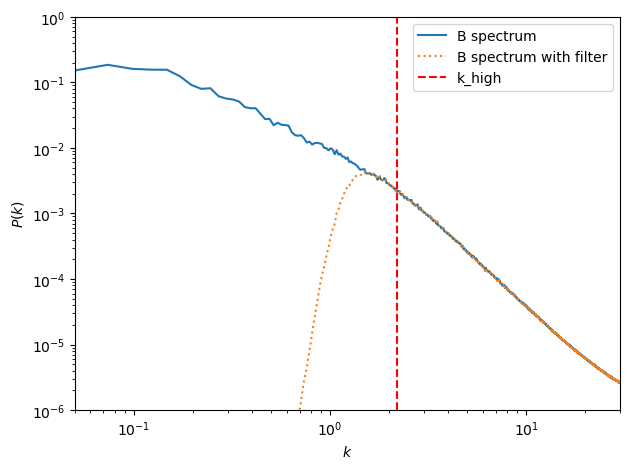

In [22]:
# Plot unfiltered first and capture line objects
plt.rcdefaults()

line_B, = plt.loglog(
    spectrum_B.kk,
    spectrum_B.sp,
    label="B spectrum"
)

plt.loglog(
    spectrum_Bf.kk,
    spectrum_Bf.sp,
    linestyle=":",
    label="B spectrum with filter"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
plt.axvline(x=k_high, linestyle='--', color='red', label='k_high')

plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "B_Spectrum", dpi=300)
plt.show()

In [23]:
data_Jx =  partial_y_fft(data_Bz, dx)
data_Jy = -partial_x_fft(data_Bz, dx)
data_Jz =  partial_x_fft(data_By, dx) - partial_y_fft(data_Bx, dx)

spectrum_Jx = compute_radial_spectrum(data_Jx, dx, dy)
spectrum_Jy = compute_radial_spectrum(data_Jy, dx, dy)
spectrum_Jz = compute_radial_spectrum(data_Jz, dx, dy)

spectrum_J = np.recarray(spectrum_Jx.shape, dtype=spectrum_Jx.dtype)
spectrum_J.kk = spectrum_Jx.kk
spectrum_J.sp = spectrum_Jx.sp + spectrum_Jy.sp + spectrum_Jz.sp

data_Jx_filtered = partial_y_fft(data_Bz_filtered,dx)
data_Jy_filtered = -partial_x_fft(data_Bz_filtered,dy)
data_Jz_filtered = partial_x_fft(data_By_filtered,dy)-partial_y_fft(data_Bx_filtered,dx)

spectrum_Jxf = compute_radial_spectrum(data_Jx_filtered, dx, dy)
spectrum_Jyf = compute_radial_spectrum(data_Jy_filtered, dx, dy)
spectrum_Jzf = compute_radial_spectrum(data_Jz_filtered, dx, dy)

spectrum_Jf = np.recarray(spectrum_Jxf.shape, dtype=spectrum_Jxf.dtype)
spectrum_Jf.kk = spectrum_Jxf.kk
spectrum_Jf.sp = spectrum_Jxf.sp + spectrum_Jyf.sp + spectrum_Jzf.sp

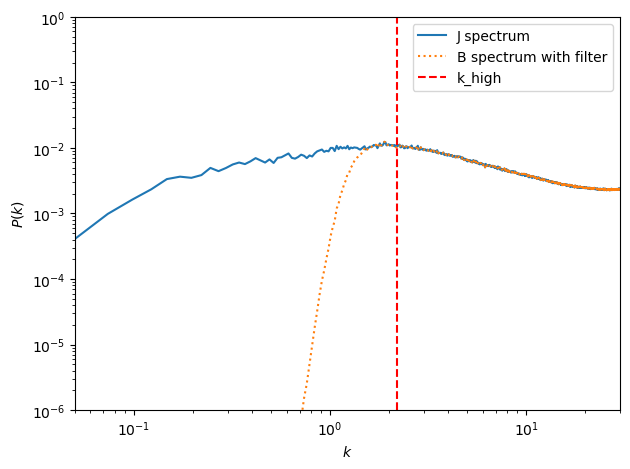

In [24]:
# Plot unfiltered first and capture line objects
plt.rcdefaults()

line_J, = plt.loglog(
    spectrum_J.kk,
    spectrum_J.sp,
    label="J spectrum"
)

plt.loglog(
    spectrum_Jf.kk,
    spectrum_Jf.sp,
    linestyle=":",
    label="B spectrum with filter"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
plt.axvline(x=k_high, linestyle='--', color='red', label='k_high')

plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "J_Spectrum", dpi=300)
plt.show()

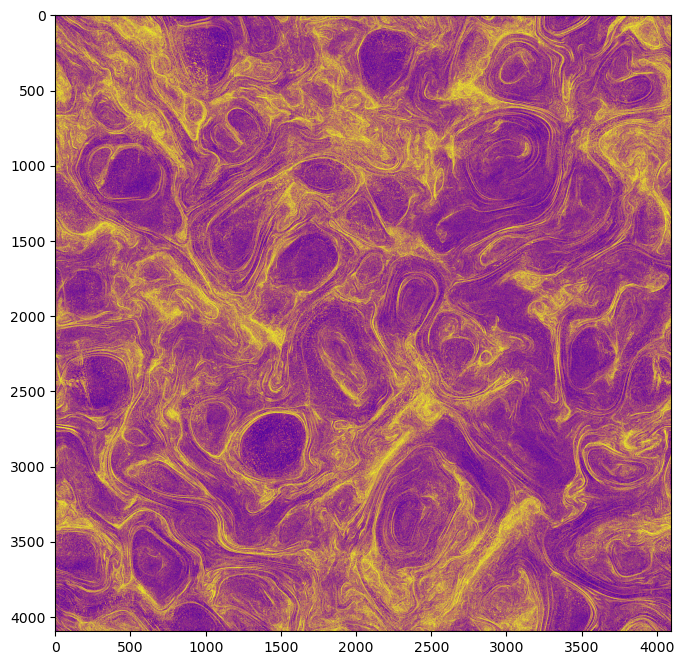

In [25]:
# 2. Plot the 2D matrix
plt.figure(figsize=(10, 8))
data_mod_Jz_filtered = np.abs(data_Jz_filtered)

# Basic image plot
img = plt.imshow(data_mod_Jz_filtered, cmap='plasma', vmax=0.5)  # You can change the colormap (e.g., 'hot', 'plasma', 'gray')

# Add titles and labels

# Show the plot
# plt.savefig("B.png", dpi = 5000)
plt.show()